# Notebook 12: Reduced-Class Slot Tasks

The 31-class intent task is demanding for a classifier built on utterance-level statistics, which reached roughly 24% accuracy in Notebook 07. Because every intent is the combination of three slot values, three reduced-class tasks follow directly from the label structure of Fluent Speech Commands: **action** (6 classes), **object** (14 classes) and **location** (4 classes). No intents are removed and no classes are hand-selected; each utterance is simply labelled with one slot value.

This notebook reports the slot tasks for representative models of each tier:

- SVM and MLP on prosodic statistics and on prosodic + MFCC statistics (Notebooks 06-07), using the configurations selected on the official validation split;
- the 1D-CNN on 40-band log-mel sequences (Notebook 10);
- the 1D-CNN on frozen wav2vec 2.0 frame sequences (Notebook 11).

All models use the same five speaker-grouped folds as Notebooks 08-11, so the utterance-level classifiers are also reported under cross-validation here for the first time. Results were produced by `src/experiments/utterance_cv.py` and `src/experiments/sequence_cv.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT = "../results"
TASKS = [("location", 4), ("action", 6), ("object", 14), ("intent", 31)]

utt = pd.read_csv(f"{RESULTS_ROOT}/cv_utterance_all_targets.csv")

def utterance(features, column, target):
    rows = utt[(utt.features == features) & (utt.target == target)].sort_values("fold")
    return rows[column].values

def sequence(prefix, target):
    return pd.read_csv(f"{RESULTS_ROOT}/cv_{prefix}_{target}.csv").sort_values("fold")["held_out_acc"].values

models = {
    "Majority class":           lambda t: utterance("prosodic", "majority_acc", t),
    "Prosodic + SVM":           lambda t: utterance("prosodic", "svm_acc", t),
    "Prosodic + MLP":           lambda t: utterance("prosodic", "mlp_acc", t),
    "Prosodic + MFCC + SVM":    lambda t: utterance("prosodic_mfcc", "svm_acc", t),
    "Prosodic + MFCC + MLP":    lambda t: utterance("prosodic_mfcc", "mlp_acc", t),
    "1D-CNN, log-mel":          lambda t: sequence("cnn_logmel", t),
    "wav2vec 2.0 + 1D-CNN":     lambda t: sequence("wav2vec2_sequence", t),
}
scores = {m: {t: 100 * f(t) for t, _ in TASKS} for m, f in models.items()}
table = pd.DataFrame({m: {f"{t} ({k})": f"{s[t].mean():.1f} ± {s[t].std(ddof=1):.1f}" for t, k in TASKS}
                      for m, s in scores.items()}).T
table

,location (4),action (6),object (14),intent (31)
Majority class,61.2 ± 0.3,25.8 ± 0.3,31.2 ± 0.4,10.0 ± 0.2
Prosodic + SVM,62.6 ± 1.1,35.8 ± 1.2,42.9 ± 1.5,17.8 ± 1.0
Prosodic + MLP,62.6 ± 1.8,34.4 ± 1.8,41.7 ± 2.1,16.5 ± 1.5
Prosodic + MFCC + SVM,64.3 ± 1.0,40.7 ± 1.5,49.3 ± 2.1,24.0 ± 1.0
Prosodic + MFCC + MLP,60.5 ± 1.3,34.3 ± 1.5,42.4 ± 1.9,21.4 ± 1.0
"1D-CNN, log-mel",90.6 ± 3.5,85.1 ± 5.1,89.1 ± 3.1,79.4 ± 6.8
wav2vec 2.0 + 1D-CNN,97.5 ± 1.0,95.1 ± 2.0,96.4 ± 1.7,93.1 ± 3.1


## Accuracy relative to the majority class

The majority-class accuracy differs widely between tasks (the location value *none* alone accounts for about 61% of utterances), so raw accuracies are not directly comparable across tasks. The fraction of the majority-class error that a model removes, $(a - a_{maj}) / (100 - a_{maj})$, places all tasks on a common scale: 0 means no better than always predicting the most frequent class, and 1 means perfect accuracy.

In [2]:
majority = {t: scores["Majority class"][t].mean() for t, _ in TASKS}
reduction = pd.DataFrame({m: {f"{t} ({k})": (s[t].mean() - majority[t]) / (100 - majority[t])
                              for t, k in TASKS}
                          for m, s in scores.items() if m != "Majority class"}).T
reduction.round(3)

,location (4),action (6),object (14),intent (31)
Prosodic + SVM,0.038,0.135,0.171,0.086
Prosodic + MLP,0.036,0.116,0.152,0.073
Prosodic + MFCC + SVM,0.080,0.200,0.263,0.155
Prosodic + MFCC + MLP,-0.016,0.114,0.163,0.127
"1D-CNN, log-mel",0.759,0.799,0.842,0.771
wav2vec 2.0 + 1D-CNN,0.936,0.934,0.947,0.923


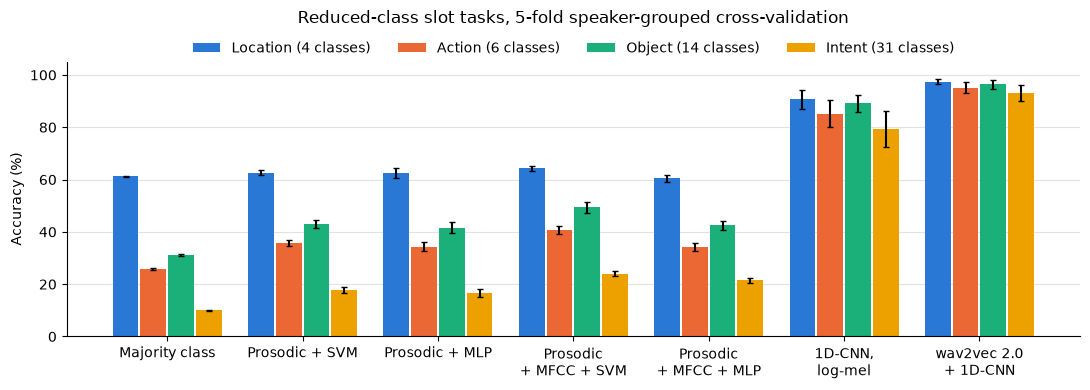

In [3]:
colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
names = list(scores)
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.19
for j, (t, k) in enumerate(TASKS):
    x = np.arange(len(names)) + (j - 1.5) * (width + 0.015)
    ax.bar(x, [scores[n][t].mean() for n in names], width=width, color=colours[j],
           yerr=[scores[n][t].std(ddof=1) for n in names], capsize=2, label=f"{t.capitalize()} ({k} classes)")
ax.set_xticks(np.arange(len(names)))
ax.set_xticklabels([n.replace(" + MFCC", "\n+ MFCC").replace(", ", ",\n").replace("wav2vec 2.0 + ", "wav2vec 2.0\n+ ") for n in names])
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 105); ax.yaxis.grid(True, color="#e3e2de"); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.12))
ax.set_title("Reduced-class slot tasks, 5-fold speaker-grouped cross-validation", pad=28)
plt.tight_layout(); plt.show()

## Utterance-level classifiers under cross-validation

Notebooks 06 and 07 reported the utterance-level classifiers on the official ten-speaker test split. The same configurations under the shared speaker-grouped folds are compared below with those figures.

In [4]:
from scipy import stats

fixed_split = {"Prosodic + SVM": 16.5, "Prosodic + MLP": 14.3, "Prosodic + MFCC + SVM": 25.8, "Prosodic + MFCC + MLP": 21.0}
cv_intent = pd.DataFrame({m: {"official test split (%)": fixed_split[m],
                              "5-fold CV mean (%)": scores[m]["intent"].mean(),
                              "5-fold CV std (%)": scores[m]["intent"].std(ddof=1)} for m in fixed_split}).T
print(cv_intent.round(1).to_string())

gain = scores["Prosodic + MFCC + SVM"]["intent"] - scores["Prosodic + SVM"]["intent"]
p = stats.ttest_rel(scores["Prosodic + MFCC + SVM"]["intent"], scores["Prosodic + SVM"]["intent"]).pvalue
print(f"\nMFCC statistics vs. prosodic only (SVM): {gain.mean():+.1f} points, higher in {(gain > 0).sum()}/5 folds, p = {p:.4f}")

                       official test split (%)  5-fold CV mean (%)  5-fold CV std (%)
Prosodic + SVM                            16.5                17.8                1.0
Prosodic + MLP                            14.3                16.5                1.5
Prosodic + MFCC + SVM                     25.8                24.0                1.0
Prosodic + MFCC + MLP                     21.0                21.4                1.0

MFCC statistics vs. prosodic only (SVM): +6.2 points, higher in 5/5 folds, p = 0.0004


## Results

Reducing the number of classes raised accuracy for every model. The SVM on prosodic and MFCC statistics improved from 24.0% on the 31-class intent to 40.7% on the action, 49.3% on the object and 64.3% on the location. These gains, however, largely follow the rise of the majority-class baseline (10.0%, 25.8%, 31.2% and 61.2% respectively). Measured as the fraction of the majority-class error removed, the SVM achieves 0.16 on the intent, 0.20 on the action, 0.26 on the object and only 0.08 on the location; the MLP on the same features falls below the majority class on the location task (60.5% against 61.2%). The location is unspoken in most utterances and, when present, is a single word near the end of the command, a cue that utterance-level averages capture poorly.

The sequence models behave differently. The log-mel CNN reaches 85.1-90.6% on the slot tasks and the wav2vec 2.0 network 95.1-97.5%, removing 0.76-0.84 and 0.92-0.95 of the majority-class error respectively, with little variation between tasks. A smaller label set therefore improves the headline accuracy of the classical pipeline without changing its position relative to the other tiers: the limiting factor is the loss of temporal information in the utterance-level representation rather than the number of classes.

Under cross-validation, the utterance-level classifiers give 17.8% ± 1.0% (prosodic) and 24.0% ± 1.0% (prosodic + MFCC) for the SVM, close to the official-split figures of 16.5% and 25.8%. The MFCC statistics improve every fold (+6.2 points, p < 0.001), so the conclusions of Notebooks 06 and 07 hold under the stricter protocol.